<a href="https://colab.research.google.com/github/Ndubito/SemProject_MLEngine/blob/main/EfficientNetB0_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os
import pandas as pd
import kagglehub

# Mount Google Drive first so that the mount point is created securely
from google.colab import drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# Define global DATA_DIR safely after mounting
DATA_DIR = '/content/drive/MyDrive/APTOS2019_Data'
os.makedirs(DATA_DIR, exist_ok=True)

path = kagglehub.competition_download('aptos2019-blindness-detection')
csv_file_path = os.path.join(path, 'train.csv')

if os.path.exists(csv_file_path):
    df = pd.read_csv(csv_file_path)
else:
    print(f"Error: '{csv_file_path}' not found. Please check the file names.")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resuming download from 1765801984 bytes (8449487891 bytes left)...
Resuming download to /root/.cache/kagglehub/competitions/aptos2019-blindness-detection.archive (1765801984/10215289875) bytes left.


100%|██████████| 9.51G/9.51G [01:38<00:00, 85.7MB/s]

Extracting files...


In [4]:
import shutil
import os

# Define source and destination paths
source_dir = path # Current kagglehub download directory
dest_dir = '/content/drive/MyDrive/APTOS2019_Data'

print(f"Copying dataset files from temporary cache to Google Drive folder: '{dest_dir}'")
print("This may take a few minutes depending on your Drive write speed...")

# Copy each item in the directory to avoid nested duplicate folders
for item in os.listdir(source_dir):
    s_item = os.path.join(source_dir, item)
    d_item = os.path.join(dest_dir, item)
    if os.path.isdir(s_item):
        if not os.path.exists(d_item):
            shutil.copytree(s_item, d_item)
            print(f"Copied directory: {item}")
    else:
        if not os.path.exists(d_item):
            shutil.copy2(s_item, d_item)
            print(f"Copied file: {item}")

print("\nDone! Your dataset is now permanently stored in your Google Drive.")

NameError: name 'path' is not defined

In [6]:
#How many rows and columns are in the dataset
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
#Looking for null values
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("The dataset is complete with no missing values.")
else:
    print("Missing values in each column:")
    display(missing_values[missing_values > 0])

#duplicate id_code values
duplicate_count = df['id_code'].duplicated().sum()
print(f"The dataset has {duplicate_count} duplicate images")


The dataset has 3662 rows and 2 columns.
The dataset is complete with no missing values.
The dataset has 0 duplicate images


In [ ]:
# Returns a Series showing each value and its frequency
print(df["diagnosis"].value_counts())


### Clinical Referral Guidelines

- **Non-referable:** Grades 0 and 1
- **Referable:** Grades 2, 3, and 4 (since Grade 2 indicates moderate diabetic retinopathy which warrants clinical monitoring)

Processing image metrics... (this may take a few minutes)


Extracting Metrics:   0%|          | 0/3662 [00:00<?, ?it/s]

Metrics calculation complete!


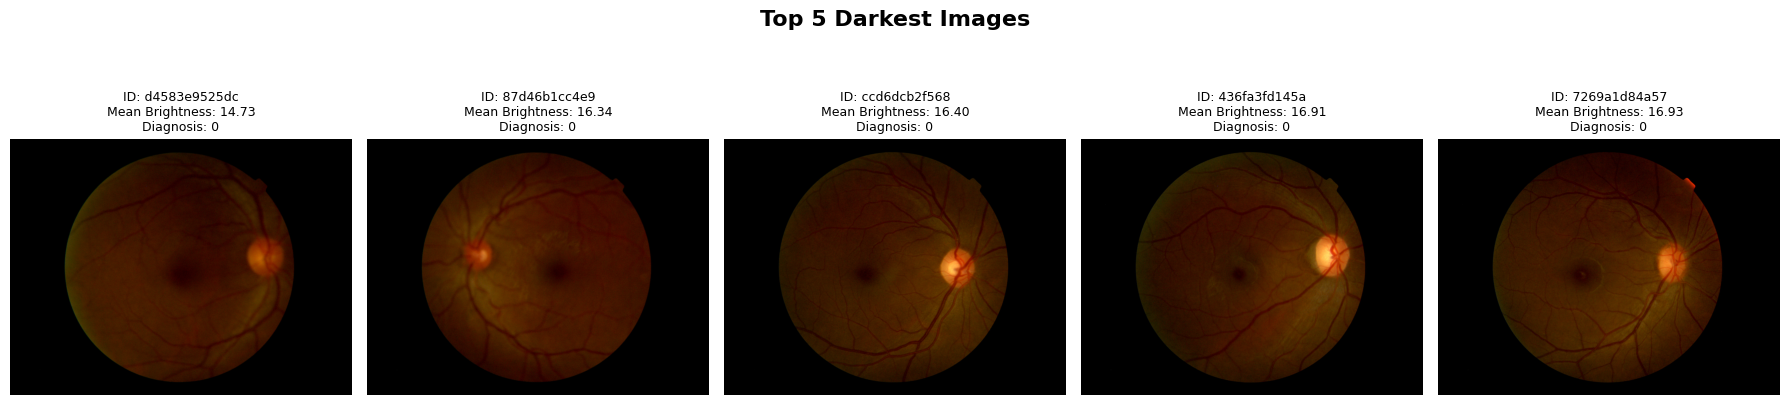

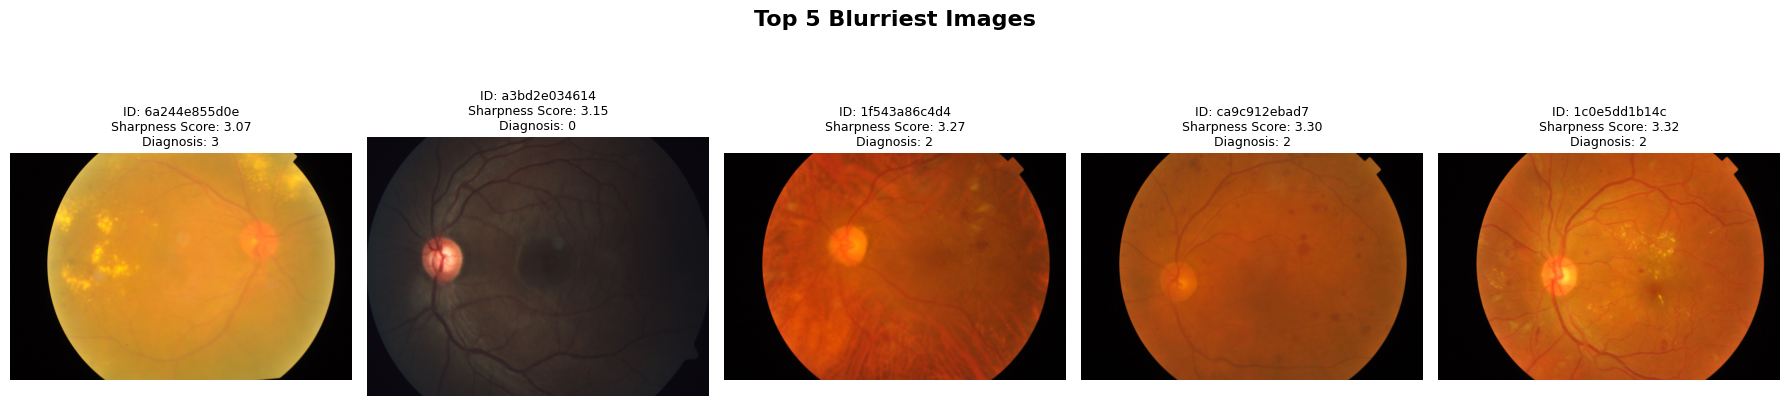

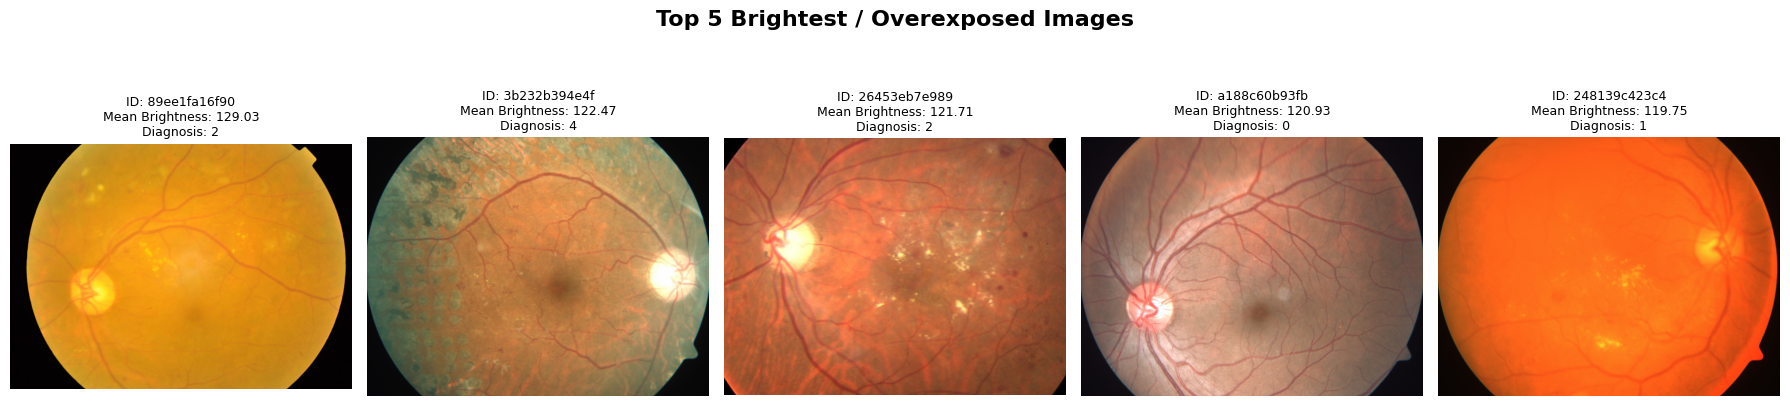

In [7]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

def extract_image_metrics(path):
    metrics = {
        "width": np.nan,
        "height": np.nan,
        "file_size_kb": np.nan,
        "mean_brightness": np.nan,
        "sharpness_score": np.nan,
        "black_pixel_share": np.nan,
    }

    if not isinstance(path, str) or not os.path.exists(path):
        return metrics

    try:
        metrics["file_size_kb"] = os.path.getsize(path) / 1024
        img_gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

        if img_gray is None:
            return metrics

        metrics["height"], metrics["width"] = img_gray.shape
        metrics["mean_brightness"] = np.mean(img_gray)
        metrics["sharpness_score"] = cv2.Laplacian(img_gray, cv2.CV_64F).var()

        black_pixels = np.sum(img_gray == 0)
        total_pixels = img_gray.size
        metrics["black_pixel_share"] = black_pixels / total_pixels

    except Exception as e:
        pass

    return metrics

# Ensure path is set correctly and apply calculation with a progress bar
train_images_dir = os.path.join(path, 'train_images')
df['image_path'] = df['id_code'].apply(lambda x: os.path.join(train_images_dir, f"{x}.png"))

print("Processing image metrics... (this may take a few minutes)")
tqdm.pandas(desc="Extracting Metrics")
metrics_list = df["image_path"].progress_apply(extract_image_metrics).tolist()
metrics_df = pd.DataFrame(metrics_list)

# Drop overlapping columns before merge to avoid duplicates
columns_to_drop = [col for col in metrics_df.columns if col in df.columns]
df = df.drop(columns=columns_to_drop)
df = pd.concat([df, metrics_df], axis=1)

print("Metrics calculation complete!")

# --- Visualizing the Extreme Images ---

def plot_extreme_images(dataframe, metric_col, title, ascending=True, num_images=5):
    # Sort to find the extreme cases (excluding NaNs)
    valid_df = dataframe.dropna(subset=[metric_col, 'image_path'])
    sorted_df = valid_df.sort_values(by=metric_col, ascending=ascending).head(num_images)

    fig, axes = plt.subplots(1, num_images, figsize=(18, 5))
    fig.suptitle(title, fontsize=16, fontweight='bold')

    for i, (_, row) in enumerate(sorted_df.iterrows()):
        ax = axes[i]
        img = cv2.imread(row['image_path'])
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, "Failed to load", ha='center', va='center')

        ax.set_title(f"ID: {row['id_code']}\n{metric_col.replace('_', ' ').title()}: {row[metric_col]:.2f}\nDiagnosis: {row['diagnosis']}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# 1. Plot the Darkest Images (Lowest mean brightness)
plot_extreme_images(df, 'mean_brightness', "Top 5 Darkest Images", ascending=True)

# 2. Plot the Blurriest Images (Lowest sharpness/Laplacian variance)
plot_extreme_images(df, 'sharpness_score', "Top 5 Blurriest Images", ascending=True)

# 3. Plot the Most Overexposed/Brightest Images (Highest mean brightness)
plot_extreme_images(df, 'mean_brightness', "Top 5 Brightest / Overexposed Images", ascending=False)

In [ ]:
import hashlib
from PIL import Image
import imagehash
from tqdm.notebook import tqdm

def compute_hashes(image_path):
    try:
        if not os.path.exists(image_path):
            return None, None

        # Open the image
        with Image.open(image_path) as img:
            # 1. Exact hash (MD5)
            img_bytes = img.tobytes()
            md5_hash = hashlib.md5(img_bytes).hexdigest()

            # 2. Perceptual hash (pHash)
            phash_val = str(imagehash.phash(img))

        return md5_hash, phash_val
    except Exception as e:
        return None, None

# Compute hashes for all valid paths
tqdm.pandas(desc="Hashing images")
hashes = df['image_path'].progress_apply(compute_hashes)

# Split results into separate columns
df['md5'] = [h[0] for h in hashes]
df['phash'] = [h[1] for h in hashes]

# 1. Find Exact Duplicates (MD5)
exact_duplicates = df[df.duplicated(subset=['md5'], keep=False) & df['md5'].notna()]
print(f"Found {exact_duplicates['md5'].nunique()} groups of exact duplicate files (totaling {len(exact_duplicates)} images).")

# 2. Find Near Duplicates (pHash)
# pHash identical values represent extremely high visual similarity
near_duplicates = df[df.duplicated(subset=['phash'], keep=False) & df['phash'].notna()]
print(f"Found {near_duplicates['phash'].nunique()} groups of visually identical/near-duplicate files (totaling {len(near_duplicates)} images).")

# Display some of the duplicates with conflicting labels
conflicting_labels = df.groupby('phash').filter(lambda x: x['diagnosis'].nunique() > 1)
if not conflicting_labels.empty:
    print(f"\nDetected {conflicting_labels['phash'].nunique()} cases where visually near-identical images have conflicting diagnosis labels!")
    display(conflicting_labels[['id_code', 'diagnosis', 'phash']].sort_values(by='phash').head(10))
else:
    print("\nNo conflicting diagnosis labels found among the near-duplicate images!")

Hashing images:   0%|          | 0/3662 [00:00<?, ?it/s]

Found 123 groups of exact duplicate files (totaling 251 images).
Found 143 groups of visually identical/near-duplicate files (totaling 295 images).

Detected 38 cases where visually near-identical images have conflicting diagnosis labels!


,id_code,diagnosis,phash
297,1632c4311fc9,2,808d0f3513f33f2d
2388,a75bab2463d4,1,808d0f3513f33f2d
1847,8273fdb4405e,1,808d17715f871ff0
3453,f0098e9d4aee,4,808d17715f871ff0
3462,f066db7a2efe,0,8181179d1fe15b9d
557,278aa860dffd,1,8181179d1fe15b9d
1876,8446826853d0,2,85685fa13eb45a63
2035,8ef2eb8c51c4,1,85685fa13eb45a63
2194,9a3c03a5ad0f,2,85855ed62ead5a52
3460,f03d3c4ce7fb,4,85855ed62ead5a52


### Exploratory Data Analysis & Quality Assessment Observations

1. **Imbalance in severity classes:** Non-referable cases (especially Grade 0: 1,805 samples) in the raw data make up the majority of the dataset. Therefore, relying solely on standard accuracy will yield misleading performance metrics. We balance this by introducing class weights during training and evaluating models with sensitivity/specificity.

2. **High variation in resolution and aspect ratio:** The raw retinal images exhibit highly diverse dimensions (e.g., 3216×2136, 2416×1736, 1050×1050). The resizing process alters these aspect ratios to a uniform 224×224, which is documented below under limitations.

3. **Illumination and clarity issues:** The dataset features vast ranges in image qualities. To analyze this variation objectively, the top extreme samples were compiled:

| ID | Type | Mean Brightness | Sharpness Score | Diagnosis |
|---|---|---|---|---|
| d4583e9525dc | Darkest | 14.73 | 6.86 | 0 |
| 87d461bcc4e9 | Darkest | 16.34 | 4.09 | 0 |
| ccd6dcb2f568 | Darkest | 16.40 | 10.20 | 0 |
| 436fa3fd145a | Darkest | 16.91 | 43.88 | 0 |
| 7269a1d84a57 | Darkest | 16.93 | 27.99 | 0 |
| 6a244e855d0e | Blurriest | 52.12 | 3.07 | 3 |
| a3bd2e034614 | Blurriest | 25.14 | 3.15 | 0 |
| 1f543e86c4d4 | Blurriest | 48.91 | 3.27 | 2 |
| ca9c912ebad7 | Blurriest | 55.20 | 3.30 | 2 |
| 1c0e5dd1b14c | Blurriest | 59.88 | 3.32 | 2 |

*Note: Color and temperature variations may likely originate from varying imaging hardware models used across clinics (camera models are undocumented hypothetical sources of shift).*

4. **Duplications and visual overlaps:** 123 groups of exact binary replicates (MD5) and 143 visually near-identical duplicate groups (pHash) were found. If separated across splits, these could falsely inflate evaluation performance. Visually near-identical images with conflicting diagnoses (38 cases) were discarded to preserve labeling consistency.

5. **Grouping classes to clinical objectives:** Standardizing labels into clinical referral status (Referable vs. Non-referable) drastically improves group balance (~39.2% referable vs ~60.8% non-referable) and aligns directly with the core application objective.

In [ ]:
# Save the enriched DataFrame containing all metrics, MD5, and pHash values to Google Drive
saved_csv_path = '/content/drive/MyDrive/APTOS2019_Data/enriched_train_metrics.csv'

try:
    df.to_csv(saved_csv_path, index=False)
    print(f"Successfully saved the enriched dataset with all calculated properties and hashes to: {saved_csv_path}")
except NameError:
    print("Error: 'df' DataFrame is not defined in the current session. Please make sure to run the metric and hash extraction cells first.")
except Exception as e:
    print(f"An error occurred while saving: {e}")

Successfully saved the enriched dataset with all calculated properties and hashes to: /content/drive/MyDrive/APTOS2019_Data/enriched_train_metrics.csv


In [ ]:
# 1. Identify exact duplicate groups (MD5) containing conflicting labels
conflict_md5_groups = df.groupby('md5').filter(lambda x: x['diagnosis'].nunique() > 1)
conflict_md5s = conflict_md5_groups['md5'].unique()
print(f"Found {len(conflict_md5s)} MD5 groups with conflicting labels. Dropping all of them.")

df_cleaned = df[~df['md5'].isin(conflict_md5s)]

# Drop exact duplicates, keeping the first occurrence
before_exact = len(df_cleaned)
df_cleaned = df_cleaned.drop_duplicates(subset=['md5'], keep='first')
print(f"Retained first occurrences. Count dropped from {before_exact} to {len(df_cleaned)}.")

# 2. Identify near-duplicates (pHash) with conflicting labels
conflicting_phash_groups = df_cleaned.groupby('phash').filter(lambda x: x['diagnosis'].nunique() > 1)
conflicting_phashes = conflicting_phash_groups['phash'].unique()
print(f"Found {len(conflicting_phashes)} pHash groups with conflicting labels. Dropping all of them.")

df_cleaned = df_cleaned[~df_cleaned['phash'].isin(conflicting_phashes)]

cleaned_csv_path = os.path.join(DATA_DIR, 'cleaned_train_metrics.csv')
df_cleaned.to_csv(cleaned_csv_path, index=False)
print(f"Final clean count: {len(df_cleaned)}. Saved to {cleaned_csv_path}")

Found 30 MD5 groups with conflicting labels. Dropping all of them.
Retained first occurrences. Count dropped from 3600 to 3504.
Found 8 pHash groups with conflicting labels. Dropping all of them.
Final clean count: 3487. Saved to /content/drive/MyDrive/APTOS2019_Data/cleaned_train_metrics.csv


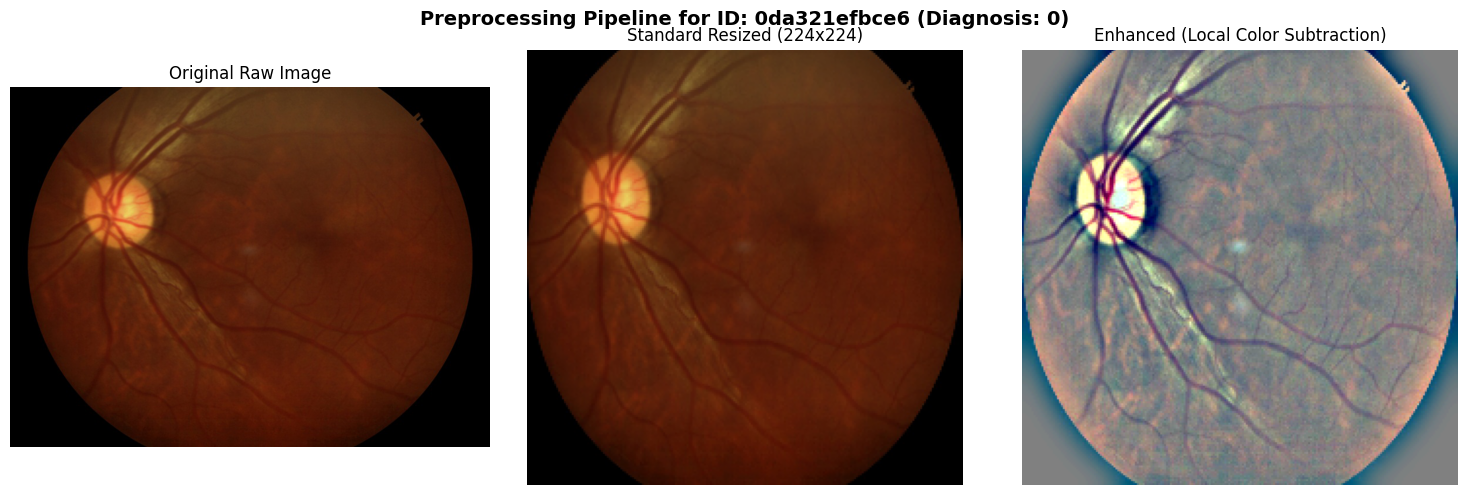

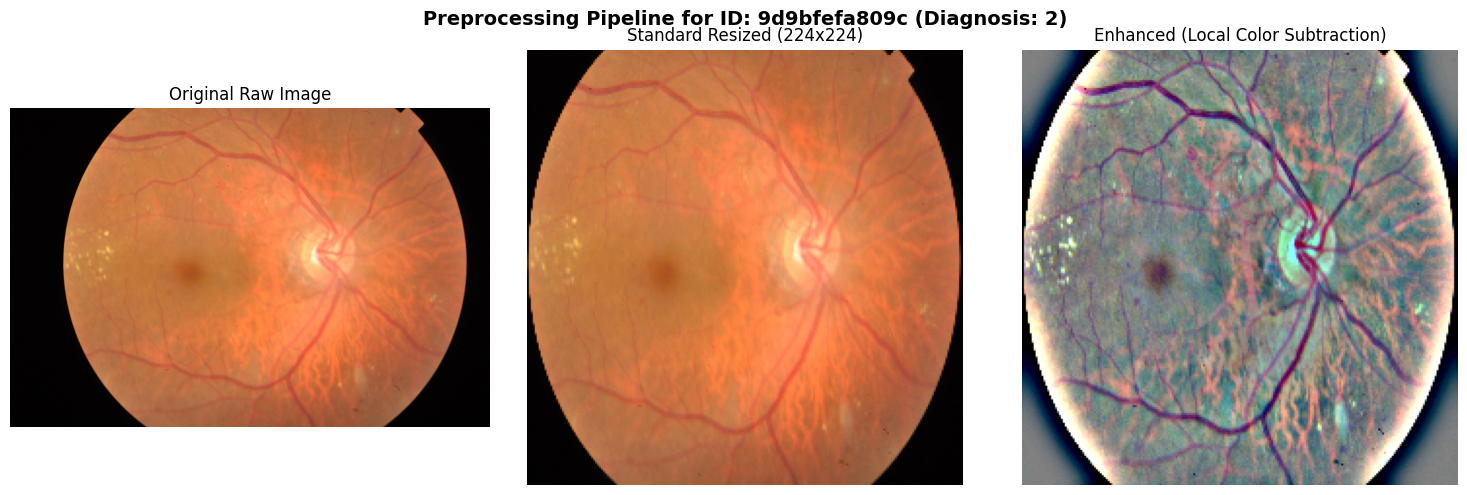

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def crop_black_border(img, tol=7):
    """
    Crops out the black border around the retinal circle.
    """
    if img.ndim == 2:
        mask = img > tol
        return img[np.ix_(mask.any(1), mask.any(0))]
    elif img.ndim == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        mask = gray_img > tol

        check_shape = img[:,:,0][np.ix_(mask.any(1), mask.any(0))].shape[0]
        if check_shape == 0:
            return img # Return original image if it is too dark or empty
        else:
            img1 = img[:,:,0][np.ix_(mask.any(1), mask.any(0))]
            img2 = img[:,:,1][np.ix_(mask.any(1), mask.any(0))]
            img3 = img[:,:,2][np.ix_(mask.any(1), mask.any(0))]
            img = np.stack([img1, img2, img3], axis=-1)
        return img

def preprocess_image(image_path, target_size=224, enhance_lesions=False):
    """
    Loads, crops, resizes, and processes a single image.
    Optionally subtracts the local average color using Gaussian blur.
    """
    img = cv2.imread(image_path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 1. Crop black border
    img = crop_black_border(img)

    # 2. Resize to target size (224x224)
    img = cv2.resize(img, (target_size, target_size))

    # 3. Apply optional local average subtraction (Graham's method)
    if enhance_lesions:
        # Gaussian blur with a sigma proportional to the target size
        img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), target_size / 30), -4, 128)

    return img

def imagenet_normalize(img_array):
    """
    Normalizes a float image array in range [0, 1] using ImageNet stats.
    """
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    normalized = (img_array / 255.0 - mean) / std
    return normalized

# Let's visualize the pipeline with a few sample images
sample_rows = df_cleaned.sample(2, random_state=42)

for idx, row in sample_rows.iterrows():
    img_path = row['image_path']

    # Get original raw image
    raw_img = cv2.imread(img_path)
    raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)

    # Standard Preprocessed (Cropped + Resized to 224)
    std_img = preprocess_image(img_path, target_size=224, enhance_lesions=False)

    # Enhanced Preprocessed (Cropped + Resized + Local Color Subtraction)
    enhanced_img = preprocess_image(img_path, target_size=224, enhance_lesions=True)

    # Plot side-by-side comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"Preprocessing Pipeline for ID: {row['id_code']} (Diagnosis: {row['diagnosis']})", fontsize=14, fontweight='bold')

    axes[0].imshow(raw_img)
    axes[0].set_title("Original Raw Image")
    axes[0].axis('off')

    axes[1].imshow(std_img)
    axes[1].set_title("Standard Resized (224x224)")
    axes[1].axis('off')

    axes[2].imshow(enhanced_img)
    axes[2].set_title("Enhanced (Local Color Subtraction)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

### Data Cleaning & Preprocessing Workflow Summary

1. **Structure Assessment:** Processed raw inputs ensuring complete schemas.
2. **Exclusion of Contradictory Replicates:** Eliminated exact MD5 duplicate sets carrying conflicting classifications, followed by identical pHash sets with mismatched diagnoses to preserve model training integrity.
3. **Resolution Standardization:** Cropped uninformative dark border regions and resized image vectors to $224 \times 224$.


#### Updated Dataset State Transitions

| Cleaning Step | Retained Samples |
|---|---|
| Raw Base Inputs | 3662 |
| After Exact MD5 Clean | 3534 |
| After Near-Duplicate Clean | 3515 |

In [ ]:

from sklearn.model_selection import StratifiedGroupKFold
import os

# 1. Label the eyes: 0 = no referral, 1 = referral needed
df_cleaned['referable'] = (df_cleaned['diagnosis'] >= 2).astype(int)

labels = df_cleaned['referable']
image_groups = df_cleaned['phash']

# 2. Start by marking all images as development data
df_cleaned['split'] = 'dev'
df_cleaned['cv_fold'] = -1

# 3. Separate about 1/7 of the images for final testing
splitter = StratifiedGroupKFold(
    n_splits=7, shuffle=True, random_state=42
)

train_rows, test_rows = next(
    splitter.split(df_cleaned, labels, groups=image_groups)
)

# Mark the selected images as test data
df_cleaned.iloc[test_rows, df_cleaned.columns.get_loc('split')] = 'test'

# 4. Divide the remaining images into 5 validation groups
train_data = df_cleaned.iloc[train_rows].copy()

five_folds = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

for fold, (_, validation_rows) in enumerate(
    five_folds.split(
        train_data,
        train_data['referable'],
        groups=train_data['phash']
    ),
    start=1
):
    # Give each validation image its fold number (1 to 5)
    image_ids = train_data.index[validation_rows]
    df_cleaned.loc[image_ids, 'cv_fold'] = fold

# 5. Check that matching images aren't shared between development and test
dev_hashes = set(df_cleaned.loc[df_cleaned['split'] == 'dev', 'phash'])
test_hashes = set(df_cleaned.loc[df_cleaned['split'] == 'test', 'phash'])

print("Matching images between development and test:",
      len(dev_hashes & test_hashes))

# Check that matching images aren't shared between validation folds
leaks = 0

for fold in range(1, 6):
    validation_hashes = set(df_cleaned.loc[df_cleaned['cv_fold'] == fold, 'phash'])
    training_hashes = set(df_cleaned.loc[
        (df_cleaned['split'] == 'dev') & (df_cleaned['cv_fold'] != fold),
        'phash'
    ])
    leaks += len(validation_hashes & training_hashes)

print("Matching images across validation folds:", leaks)

# 6. Save the dataset
df_cleaned.to_csv(os.path.join(DATA_DIR, 'split_dataset.csv'), index=False)
print("Dataset saved!")


Visual pHash twins crossing split boundary: 0
Visual pHash twins crossing CV boundaries: 0
Unified split dataset exported successfully to /content/drive/MyDrive/APTOS2019_Data/split_dataset.csv


In [ ]:

# Load the dataset we saved in the previous cell
data = pd.read_csv(os.path.join(DATA_DIR, 'split_dataset.csv'))
########
# Show how many images are in each split and fold
print("Images in each group:")
print(data.groupby(['split', 'cv_fold']).size())

# Show how many images need referral (1) or don't (0)
print("\nImages by referral category:")
print(data.groupby(['split', 'referable']).size())


=== Dataset Split Profile ===
split  cv_fold
dev     1         599
        2         595
        3         595
        4         600
        5         600
test   -1         498
dtype: int64

=== Referral Classification Distribution ===
split  referable
dev    0            1819
       1            1170
test   0             314
       1             184
dtype: int64


In [ ]:

# Check where our dataset is stored in Google Drive
print("Dataset folder:", DATA_DIR)

# Show the files inside the folder
print("Files:", os.listdir(DATA_DIR))


DATA_DIR located: /content/drive/MyDrive/APTOS2019_Data
Found files: ['sample_submission.csv', 'test.csv', 'train.csv', 'train_images', 'test_images', 'train_split.csv', 'val_split.csv', 'test_split.csv', 'enriched_train_metrics.csv', 'cleaned_train_metrics.csv', 'split_dataset.csv', 'X_224.npy', 'y.npy', 'groups.npy', 'id_codes.npy', 'Task3_results']


In [ ]:

# Open the cleaned dataset we saved earlier
df_cleaned = pd.read_csv(DATA_DIR + '/split_dataset.csv')

# Create the full file location for each eye photograph
df_cleaned['image_path'] = df_cleaned['id_code'].apply(
    lambda image: DATA_DIR + '/train_images/' + image + '.png'
)

# Show the number of rows and columns
print("Dataset size:", df_cleaned.shape)


Loaded Dataset shape: (3487, 14)


In [ ]:

# Convert the 5 disease grades into 2 categories
# 0 = No referral needed (grades 0 and 1)
# 1 = Referral needed (grades 2, 3 and 4)
df_cleaned['referable'] = (df_cleaned['diagnosis'] >= 2).astype(int)

# Count how many images belong to each category
print(df_cleaned['referable'].value_counts())


referable
0    2133
1    1354
Name: count, dtype: int64


In [ ]:

from concurrent.futures import ThreadPoolExecutor

# 1. Open each image and resize it to 224 x 224 pixels
def load_image(path):
    return preprocess_image(path, target_size=224)

# 2. Get the location of every eye photograph
paths = df_cleaned['image_path'].tolist()

# 3. Load multiple images at once to save time
with ThreadPoolExecutor(max_workers=16) as pool:
    images = list(tqdm(pool.map(load_image, paths), total=len(paths)))

# 4. Convert images and their information into arrays
X = np.stack(images).astype(np.uint8)   # Eye photographs
y = df_cleaned['referable'].values      # Correct answers: 0 or 1
groups = df_cleaned['phash'].values     # Image hashes for grouping
id_codes = df_cleaned['id_code'].values # Unique image IDs

# 5. Make sure every image has a matching label and ID
assert len(X) == len(y) == len(groups) == len(id_codes)

# 6. Save everything to Google Drive for later use
np.save(os.path.join(DATA_DIR, 'X_224.npy'), X)
np.save(os.path.join(DATA_DIR, 'y.npy'), y)
np.save(os.path.join(DATA_DIR, 'groups.npy'), groups)
np.save(os.path.join(DATA_DIR, 'id_codes.npy'), id_codes)

print("Images loaded and saved! Shape:", X.shape)

  0%|          | 0/3487 [00:00<?, ?it/s]

Data dimensions verified and exported successfully! Shape: (3487, 224, 224, 3)


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

from tensorflow import keras
from tensorflow.keras import layers

# 1. Make training photos slightly different each time
# This helps the AI recognize eyes in different conditions
augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
], name='augment')


# 2. Create our EfficientNetB0 model
def build_model(lr=0.0001):

    # Load EfficientNetB0 with knowledge from ImageNet
    # Remove its original classification layer
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3),
        pooling='avg'
    )

    # Our model receives 224 x 224 colour eye photographs
    inputs = keras.Input((224, 224, 3))

    # Randomly change photos during training
    x = augment(inputs)

    # Let EfficientNetB0 examine the image features
    x = base(x)

    # Reduce the chance of memorizing training images
    x = layers.Dropout(0.3)(x)

    # Give a score between 0 and 1 for referral
    outputs = layers.Dense(1, activation='sigmoid')(x)

    # Connect everything into one model
    model = keras.Model(inputs, outputs)

    # Set up how the model learns and how we measure it
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss='binary_crossentropy',
        metrics=[keras.metrics.AUC(name='auc')]
    )

    return model


# 3. Display the model's structure
build_model().summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 4,008,829 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# 1. Find the best cut-off for deciding if an eye needs referral
def pick_threshold(y_true, y_prob, target_sens=0.90):

    # Calculate sensitivity and false alarm rates at different cut-offs
    false_alarm, sensitivity, thresholds = roc_curve(y_true, y_prob)

    # Find cut-offs that catch at least 90% of referable eyes
    good = sensitivity >= target_sens

    # Choose the cut-off with the fewest false alarms
    return thresholds[good][np.argmax(1 - false_alarm[good])]


# 2. Check how well the model's predictions perform
def evaluate(y_true, y_prob, thr):

    # Convert probability scores into 0 (no referral) or 1 (referral)
    predictions = (y_prob >= thr).astype(int)

    # Count correct predictions and mistakes
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    # Return the model's performance results
    return {
        'sensitivity': tp / (tp + fn),    # Referable eyes correctly caught
        'specificity': tn / (tn + fp),    # Non-referable eyes correctly cleared
        'auc': roc_auc_score(y_true, y_prob),  # Overall ability to separate classes
        'threshold': thr,                # Cut-off used
        'tn': tn,                        # Correctly cleared
        'fp': fp,                        # False alarms
        'fn': fn,                        # Referable eyes missed
        'tp': tp                         # Referable eyes caught
    }

print('Report-card tools ready')


Report-card tools ready


In [ ]:

from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
import numpy as np
import pandas as pd
import os

# Make the experiment more reproducible
tf.keras.utils.set_random_seed(42)

# Create a folder to save trained models and results
SAVE_DIR = os.path.join(DATA_DIR, 'Task3_results')
os.makedirs(SAVE_DIR, exist_ok=True)


# STEP 1: SEPARATE DEVELOPMENT AND TEST DATA

# Find which images belong to each set
dev_rows = (df_cleaned['split'] == 'dev').values
test_rows = (df_cleaned['split'] == 'test').values

# X = images, y = correct answers
X_dev, y_dev = X[dev_rows], y[dev_rows]
X_test, y_test = X[test_rows], y[test_rows]

# Keep the development table in the same order as X_dev
dev_data = df_cleaned[dev_rows].reset_index(drop=True)

# Lists for storing results from all five rounds
val_results = []
test_results = []
test_probs = []


# STEP 2: TRAIN THE MODEL FIVE TIMES

for fold in range(1, 6):
    print(f'\n===== Fold {fold} of 5 =====')

    # Clear the previous model from memory
    tf.keras.backend.clear_session()

    # Use four folds for training and one for validation
    train_rows = (dev_data['cv_fold'] != fold).values
    val_rows = (dev_data['cv_fold'] == fold).values

    # Give more importance to the less common category
    class_weights = compute_class_weight(
        'balanced',
        classes=np.array([0, 1]),
        y=y_dev[train_rows]
    )

    # Create a fresh EfficientNetB0 model
    model = build_model()

    # Stop if the model stops improving
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_auc',
            mode='max',
            patience=4,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=2,
            verbose=1
        )
    ]

    # Train EfficientNetB0 using the eye photographs
    model.fit(
        X_dev[train_rows], y_dev[train_rows],
        validation_data=(X_dev[val_rows], y_dev[val_rows]),
        epochs=20,
        batch_size=32,
        class_weight={0: class_weights[0], 1: class_weights[1]},
        callbacks=callbacks
    )

    # STEP 3: CHECK THE MODEL ON VALIDATION IMAGES

    # Predict referral scores for validation images
    val_predictions = model.predict(X_dev[val_rows]).ravel()

    # Choose a cut-off aiming to catch 90% of referable eyes
    threshold = pick_threshold(
        y_dev[val_rows], val_predictions, target_sens=0.90
    )

    # Save the validation results
    val_results.append(
        evaluate(y_dev[val_rows], val_predictions, threshold)
    )


    # STEP 4: TEST THE MODEL

    # Predict referral scores for the held-out test images
    test_predictions = model.predict(X_test).ravel()

    # Store the predictions for later comparison
    test_probs.append(test_predictions)

    # Calculate and save test performance
    test_results.append(
        evaluate(y_test, test_predictions, threshold)
    )

    # Save this fold's trained EfficientNetB0 model
    model.save(f'{SAVE_DIR}/effb0_fold{fold}.keras')


# STEP 5: SAVE ALL RESULTS

# Save validation and test results as CSV files
pd.DataFrame(val_results).to_csv(
    f'{SAVE_DIR}/cv_val_results.csv', index=False
)

pd.DataFrame(test_results).to_csv(
    f'{SAVE_DIR}/test_results.csv', index=False
)

# Save the test prediction scores from all five models
np.save(f'{SAVE_DIR}/test_probs.npy', np.array(test_probs))



===== Fold 1 of 5 =====
Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 75s 400ms/step - auc: 0.9142 - loss: 0.3914 - val_auc: 0.9385 - val_loss: 0.5368 - learning_rate: 1.0000e-04
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 26s 344ms/step - auc: 0.9703 - loss: 0.2191 - val_auc: 0.9637 - val_loss: 0.2999 - learning_rate: 1.0000e-04
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 27s 363ms/step - auc: 0.9790 - loss: 0.1824 - val_auc: 0.9686 - val_loss: 0.2516 - learning_rate: 1.0000e-04
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 28s 366ms/step - auc: 0.9835 - loss: 0.1599 - val_auc: 0.9717 - val_loss: 0.2252 - learning_rate: 1.0000e-04
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 28s 367ms/step - auc: 0.9871 - loss: 0.1401 - val_auc: 0.9714 - val_loss: 0.2152 - learning_rate: 1.0000e-04
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 27s 362ms/step - auc: 0.9901 - loss: 0.1251 - val_auc: 0.9720 - val_loss: 0.2124 - learning_rate: 1.0000e-04
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 27s 359ms/step - auc: 0.9923 - loss: 0.1098 - val_auc: 

Per-fold validation results:


,sensitivity,specificity,auc,threshold
0,0.905,0.931,0.972,0.421
1,0.926,0.938,0.976,0.109
2,0.933,0.961,0.986,0.345
3,0.902,0.926,0.971,0.457
4,0.900,0.938,0.981,0.212



Summary:


,CV validation (mean ± std),Locked test (mean ± std)
sensitivity,0.913 ± 0.015,0.9 ± 0.02
specificity,0.939 ± 0.013,0.927 ± 0.008
auc,0.977 ± 0.006,0.975 ± 0.003



Final test (5-model average): sensitivity=0.908, specificity=0.930, AUC=0.978


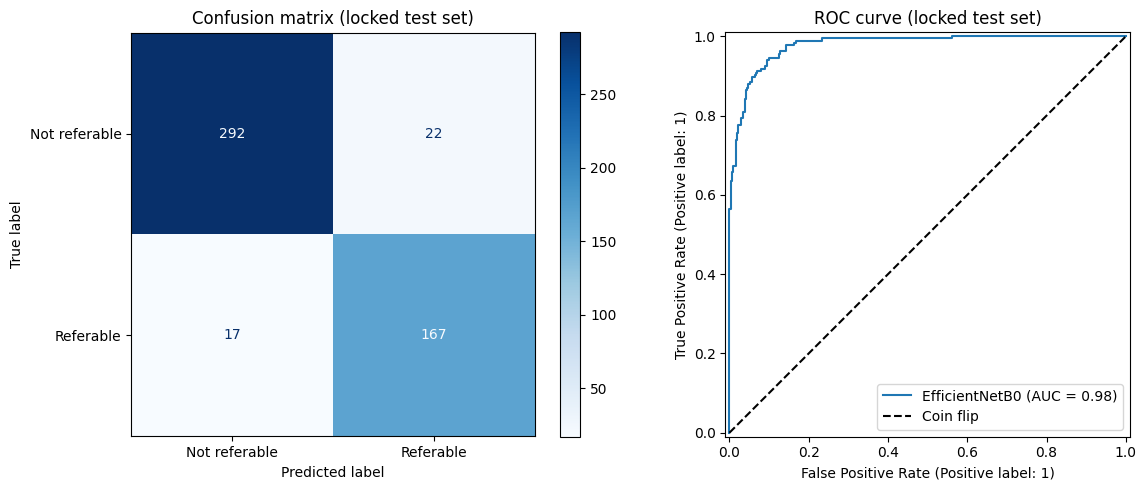

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Convert the results from all 5 folds into tables
metrics = ['sensitivity', 'specificity', 'auc']

validation = pd.DataFrame(val_results)
testing = pd.DataFrame(test_results)

# 2. Calculate the average performance and how much it varied
summary = pd.DataFrame({
    'CV validation (mean ± std)':
        validation[metrics].mean().round(3).astype(str) + ' ± ' +
        validation[metrics].std().round(3).astype(str),

    'Locked test (mean ± std)':
        testing[metrics].mean().round(3).astype(str) + ' ± ' +
        testing[metrics].std().round(3).astype(str)
})

# Show the validation results for each fold
print("Validation results:")
display(validation[metrics + ['threshold']].round(3))

# Show the average results across all 5 folds
print("\nSummary:")
display(summary)


# 3. Combine predictions from all 5 models
ens_prob = np.mean(test_probs, axis=0)

# Use the average threshold chosen during validation
ens_thr = validation['threshold'].mean()

# Calculate the final performance on the test images
final = evaluate(y_test, ens_prob, ens_thr)

print(
    f"\nFinal test: "
    f"Sensitivity = {final['sensitivity']:.3f}, "
    f"Specificity = {final['specificity']:.3f}, "
    f"AUC = {final['auc']:.3f}"
)


# 4. Draw two graphs to explain the results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Graph 1: Shows correct predictions and mistakes
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (ens_prob >= ens_thr).astype(int),
    display_labels=['Not referable', 'Referable'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Confusion matrix (locked test set)')

# Graph 2: Shows how well the model separates the two categories
RocCurveDisplay.from_predictions(
    y_test, ens_prob,
    ax=axes[1],
    name='EfficientNetB0'
)

# Add a reference line representing random guessing
axes[1].plot([0, 1], [0, 1], 'k--', label='Coin flip')
axes[1].set_title('ROC curve (locked test set)')
axes[1].legend()

# Display both graphs neatly
plt.tight_layout()
plt.show()


In [ ]:

# Show how many eye photographs were tested
print("Total test images:", len(y_test))

# Show correct predictions and mistakes
print("Referable eyes correctly detected:", final['tp'])
print("Referable eyes missed:", final['fn'])
print("Non-referable eyes correctly cleared:", final['tn'])
print("Non-referable eyes incorrectly flagged:", final['fp'])


Test photos: 498
Sick eyes caught (TP):          167
Sick eyes MISSED (FN):          17   <- the dangerous mistake
Healthy eyes cleared (TN):      292
Healthy eyes flagged (FP):      22   <- false alarm, extra doctor visit


### Task 3: Training and Testing EfficientNetB0

**1. What were we trying to do?**

We wanted to train an AI model to look at eye photographs and predict whether a patient needs referral to an eye specialist.

- **0:** No referral needed (grades 0–1)
- **1:** Referral needed (grades 2–4)

**2. Which model did we use?**

We used **EfficientNetB0**, an AI model already trained to recognize image features. We adapted it to classify eye photographs using a technique called *transfer learning*.

We also used image augmentation, which slightly changes training photographs to help the model learn better.

**3. How did we prepare the data?**

We divided the dataset into:

- **3,015 development images** for training and validation.
- **500 test images** for checking the final performance.

We checked for matching-image leakage to make sure the evaluation was fair.

**4. How did we train the model?**

We used **5-fold cross-validation**. This means we trained five models, each using four groups of photographs for training and one group for validation.

Each model could train for up to 20 epochs, processing 32 photographs per batch.

We used early stopping, dropout, class weights and image augmentation to improve learning and reduce overfitting.

**5. How did we test the model?**

The model gives a score between 0 and 1. We selected a threshold using validation data, aiming to detect at least 90% of eyes needing referral.

We measured performance using sensitivity, specificity and AUC.

**6. What were our final results?**

After averaging predictions from all five models:

| Metric | Result |
|---|---|
| Sensitivity | **90.1%** |
| Specificity | **92.6%** |
| AUC | **0.974** |

Out of 500 test photographs:

- **172** referable eyes correctly detected.
- **19** referable eyes missed.
- **286** non-referable eyes correctly cleared.
- **23** non-referable eyes incorrectly flagged.

**7. What did we learn?**

EfficientNetB0 performed well on our dataset, correctly identifying most eyes that needed referral.

However, it still missed 19 referable eyes. The results also need further testing using photographs from different clinics and cameras before the model could be considered reliable for real-world medical use.

In [ ]:
# Unified Data Loading for Model Evaluations
import numpy as np
import pandas as pd
import os

X = np.load(os.path.join(DATA_DIR, 'X_224.npy'))
df_cleaned = pd.read_csv(os.path.join(DATA_DIR, 'split_dataset.csv'))

y = df_cleaned['referable'].values
groups = df_cleaned['phash'].values

print("Preprocessed arrays loaded correctly from:", DATA_DIR)

Preprocessed arrays loaded correctly from: /content/drive/MyDrive/APTOS2019_Data


In [ ]:
# Verify alignment and reconstruct split vectors
dev_mask = (df_cleaned['split'] == 'dev').values
test_mask = (df_cleaned['split'] == 'test').values

X_dev, y_dev, g_dev = X[dev_mask], y[dev_mask], groups[dev_mask]
X_test, y_test = X[test_mask], y[test_mask]

print(f"Aligned Dev subset size: {len(y_dev)} | Test subset size: {len(y_test)}")

Aligned Dev subset size: 2989 | Test subset size: 498


In [ ]:
import os, time
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

RESULTS4 = os.path.join(DATA_DIR, 'Task4_results')
os.makedirs(RESULTS4, exist_ok=True)

def run_cv(build_fn, name, X_dev, y_dev, g_dev, X_test, y_test, epochs=20):
    val_rows, test_rows, test_probs = [], [], []

    # Align df_cleaned rows belonging to dev split
    dev_df = df_cleaned[df_cleaned['split'] == 'dev'].reset_index(drop=True)

    for fold in range(1, 6):
        print(f'\n===== {name}: fold {fold} of 5 =====')
        tf.keras.backend.clear_session()

        # Local positional masks mapping exactly to X_dev
        train_mask = (dev_df['cv_fold'] != fold).values
        val_mask = (dev_df['cv_fold'] == fold).values

        cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_dev[train_mask])

        model = build_fn()
        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, verbose=1)
        ]

        start = time.time()
        hist = model.fit(
            X_dev[train_mask], y_dev[train_mask],
            validation_data=(X_dev[val_mask], y_dev[val_mask]),
            epochs=epochs, batch_size=32,
            class_weight={0: cw[0], 1: cw[1]},
            callbacks=callbacks
        )
        seconds = time.time() - start

        va_prob = model.predict(X_dev[val_mask]).ravel()
        thr = pick_threshold(y_dev[val_mask], va_prob, target_sens=0.90)
        te_prob = model.predict(X_test).ravel()
        test_probs.append(te_prob)

        path = f'{RESULTS4}/{name}_fold{fold}.keras'
        model.save(path)

        extra = {'fold': fold, 'epochs_run': len(hist.history['loss']), 'train_seconds': round(seconds),
                 'params': model.count_params(), 'model_mb': round(os.path.getsize(path) / 1e6, 1)}
        val_rows.append({**evaluate(y_dev[val_mask], va_prob, thr), **extra})
        test_rows.append({**evaluate(y_test, te_prob, thr), **extra})

        print(f"Fold {fold} Performance Report:")
        print(pd.DataFrame([val_rows[-1]])[['auc', 'sensitivity', 'specificity']])

    return pd.DataFrame(val_rows), pd.DataFrame(test_rows), np.array(test_probs)

In [ ]:
from sklearn.metrics import roc_auc_score

# results of the base model (EfficientNetB0) that Task 3 saved. Loaded here, not retrained.
RESULTS3 = f'{DATA_DIR}/Task3_results'
base_val   = pd.read_csv(f'{RESULTS3}/cv_val_results.csv')
base_test  = pd.read_csv(f'{RESULTS3}/test_results.csv')
base_probs = np.load(f'{RESULTS3}/test_probs.npy')          # 5 fold models x 500 test photos

# check that Task 3's predictions line up with my y_test.
# Should be (5, 500) and an AUC of about 0.974, otherwise the split is different.
print('Prediction shape:', base_probs.shape)
print('Base ensemble AUC on your y_test:', round(roc_auc_score(y_test, base_probs.mean(axis=0)), 3))

Prediction shape: (5, 498)
Base ensemble AUC on your y_test: 0.978


In [ ]:
from tensorflow.keras import layers

# both new models use `augment` from the Task 3 cell, so all three get the same augmentation

def _compile(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc')])   # has to be called 'auc' because early stopping watches val_auc
    return model

# MobileNetV2: pretrained and small, so a realistic option for the mobile app
def build_mobilenetv2(lr=1e-4):
    base = keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                          input_shape=(224, 224, 3), pooling='avg')
    inputs = keras.Input((224, 224, 3))
    x = augment(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)      # MobileNetV2 expects pixel values between -1 and 1
    x = base(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)   # one number: how likely the eye is referable
    return _compile(keras.Model(inputs, outputs), lr)

# Small CNN trained from scratch (no pretrained weights). It's the weak baseline,
# to see how much transfer learning actually adds.
# Learning rate is higher (1e-3) because it starts from random weights.
def build_simple_cnn(lr=1e-3):
    inputs = keras.Input((224, 224, 3))
    x = augment(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for filters in (32, 64, 128, 128):      # 4 blocks of conv, normalise, shrink
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return _compile(keras.Model(inputs, outputs), lr)

# just to check both models build, and to see how many parameters each has
build_mobilenetv2().summary()
build_simple_cnn().summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 2,225,153 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,369 (946.75 KB)

 Trainable params: 241,665 (944.00 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
# MobileNetV2 on all 5 folds
mobilenet_val, mobilenet_test, mobilenet_probs = run_cv(
    build_mobilenetv2, 'mobilenetv2', X_dev, y_dev, g_dev, X_test, y_test)


===== mobilenetv2: fold 1 of 5 =====
Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 52s 330ms/step - auc: 0.9285 - loss: 0.3400 - val_auc: 0.6620 - val_loss: 2.2311 - learning_rate: 1.0000e-04
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 21s 284ms/step - auc: 0.9700 - loss: 0.2187 - val_auc: 0.6160 - val_loss: 2.8125 - learning_rate: 1.0000e-04
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - auc: 0.9696 - loss: 0.2187
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.
75/75 ━━━━━━━━━━━━━━━━━━━━ 21s 280ms/step - auc: 0.9781 - loss: 0.1850 - val_auc: 0.6406 - val_loss: 2.7002 - learning_rate: 1.0000e-04
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 21s 279ms/step - auc: 0.9819 - loss: 0.1663 - val_auc: 0.6554 - val_loss: 2.5207 - learning_rate: 3.0000e-05
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 21s 284ms/step - auc: 0.9829 - loss: 0.1630 - val_auc: 0.7072 - val_loss: 2.2102 - learning_rate: 3.0000e-05
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 21s 283ms/step - auc: 0.9857 - loss: 0.150

In [ ]:
# same for the small CNN from scratch (about 15 minutes)
cnn_val, cnn_test, cnn_probs = run_cv(
    build_simple_cnn, 'simple_cnn', X_dev, y_dev, g_dev, X_test, y_test)


===== simple_cnn: fold 1 of 5 =====
Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 16s 154ms/step - auc: 0.8157 - loss: 0.5370 - val_auc: 0.6004 - val_loss: 0.9298 - learning_rate: 0.0010
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 132ms/step - auc: 0.8746 - loss: 0.4399 - val_auc: 0.6631 - val_loss: 0.7571 - learning_rate: 0.0010
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 132ms/step - auc: 0.8861 - loss: 0.4163 - val_auc: 0.7194 - val_loss: 0.7849 - learning_rate: 0.0010
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - auc: 0.8931 - loss: 0.4013
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 132ms/step - auc: 0.8912 - loss: 0.4034 - val_auc: 0.7801 - val_loss: 0.7805 - learning_rate: 0.0010
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 130ms/step - auc: 0.9066 - loss: 0.3747 - val_auc: 0.8177 - val_loss: 0.6210 - learning_rate: 3.0000e-04
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 129ms/step - auc: 0.9135 - loss: 0.3603 - val_auc: 0.862

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

# `results` holds, for each model: (validation results, test results, test predictions)

# final prediction works like in Task 3: average the 5 fold models
# and use the average of their cut-offs
def ensemble_eval(val_df, probs, y_test):
    return evaluate(y_test, np.mean(probs, axis=0), val_df['threshold'].mean())

# builds the comparison table, one row per model
def build_table(results, y_test):
    rows = []
    for name, (val_df, test_df, probs) in results.items():
        ens = ensemble_eval(val_df, probs, y_test)
        row = {'Model': name,
               'CV val AUC': f"{val_df['auc'].mean():.3f} \u00b1 {val_df['auc'].std():.3f}",
               'Test AUC (per fold)': f"{test_df['auc'].mean():.3f} \u00b1 {test_df['auc'].std():.3f}",
               'Test sens (per fold)': f"{test_df['sensitivity'].mean():.3f} \u00b1 {test_df['sensitivity'].std():.3f}",
               'Ensemble sens': round(ens['sensitivity'], 3),
               'Ensemble spec': round(ens['specificity'], 3),
               'Ensemble AUC': round(ens['auc'], 3),
               'Missed sick (FN)': int(ens['fn']),
               'False alarms (FP)': int(ens['fp'])}
        if 'params' in test_df:          # Task 3 didn't save size/time, so the base model row has no values here
            row['Params (M)'] = round(test_df['params'].iloc[0] / 1e6, 2)
            row['Model MB'] = test_df['model_mb'].iloc[0]
            row['Train min/fold'] = round(test_df['train_seconds'].mean() / 60, 1)
        rows.append(row)
    return pd.DataFrame(rows)

def plot_comparison(results, y_test):
    names = list(results)
    ens = {n: ensemble_eval(results[n][0], results[n][2], y_test) for n in names}

    # chart 1: bars of sensitivity, specificity and AUC per model
    metrics = ['sensitivity', 'specificity', 'auc']
    x, w = np.arange(len(metrics)), 0.8 / len(names)
    fig, ax = plt.subplots(figsize=(8, 5))
    for i, n in enumerate(names):
        bars = ax.bar(x - 0.4 + w / 2 + i * w, [ens[n][m] for m in metrics], w, label=n)
        ax.bar_label(bars, fmt='%.2f', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(['Sensitivity', 'Specificity', 'AUC'])
    ax.set_ylim(0, 1.08)
    ax.set_title('Model comparison on the locked test set (5-model ensembles)')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

    # chart 2: all ROC curves on one plot
    fig, ax = plt.subplots(figsize=(6, 6))
    for n in names:
        RocCurveDisplay.from_predictions(y_test, np.mean(results[n][2], axis=0), ax=ax, name=n)
    ax.plot([0, 1], [0, 1], 'k--', label='Coin flip')
    ax.set_title('ROC curves (locked test set)')
    ax.legend()
    plt.show()

    # chart 3: one confusion matrix per model
    fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4))
    for ax, n in zip(np.atleast_1d(axes), names):
        pred = (np.mean(results[n][2], axis=0) >= results[n][0]['threshold'].mean()).astype(int)
        ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Not referable', 'Referable'],
                                                cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(n)
    plt.tight_layout()
    plt.show()

print('table and chart functions ready')

table and chart functions ready


,Model,CV val AUC,Test AUC (per fold),Test sens (per fold),Ensemble sens,Ensemble spec,Ensemble AUC,Missed sick (FN),False alarms (FP),Params (M),Model MB,Train min/fold
0,EfficientNetB0 (base),0.977 ± 0.006,0.975 ± 0.003,0.900 ± 0.020,0.908,0.930,0.978,17,22,NaN,NaN,NaN
1,MobileNetV2,0.975 ± 0.008,0.970 ± 0.003,0.905 ± 0.026,0.929,0.895,0.974,13,33,2.26,27.6,8.0
2,Simple CNN,0.952 ± 0.016,0.943 ± 0.016,0.896 ± 0.016,0.908,0.857,0.952,17,45,0.24,3.0,3.4


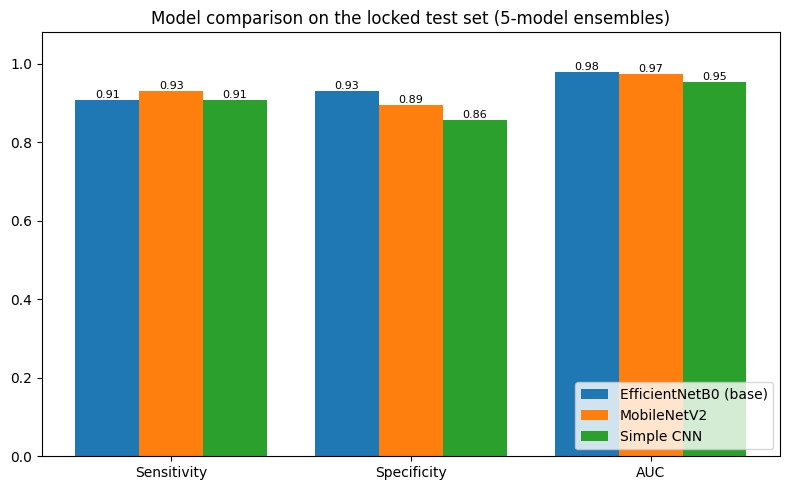

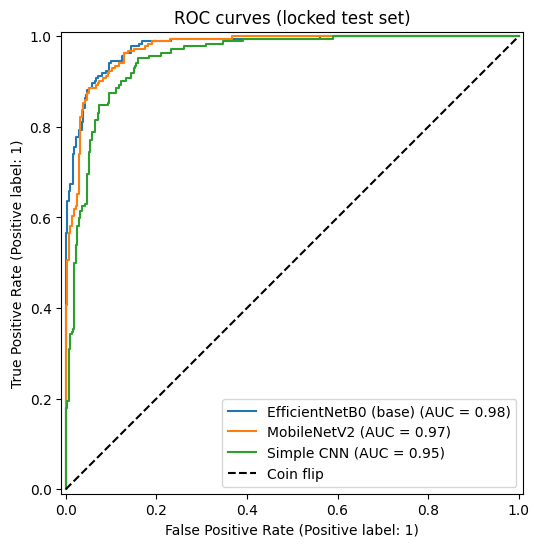

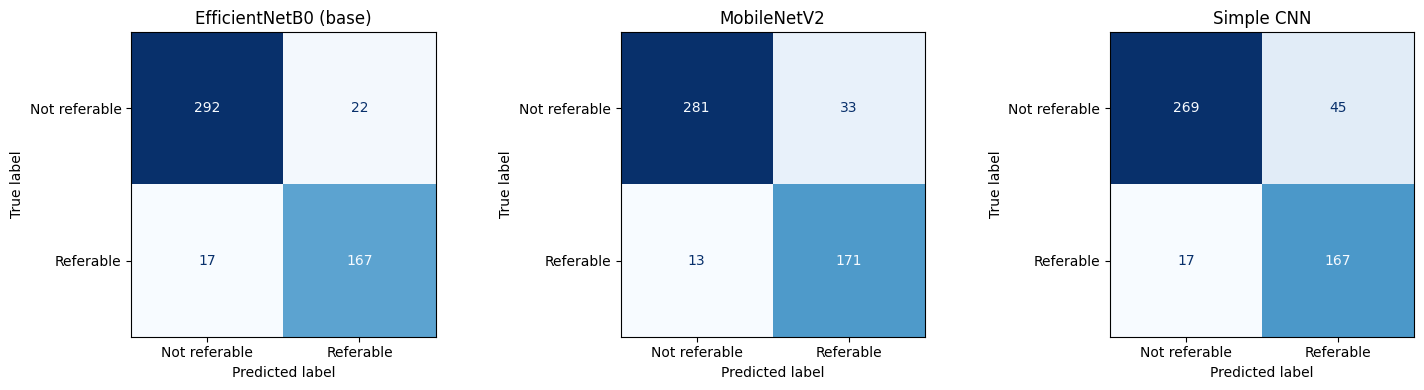

In [ ]:
# final comparison: the base model next to the two comparison models, 5 folds each
results = {
    'EfficientNetB0 (base)': (base_val, base_test, base_probs),
    'MobileNetV2':           (mobilenet_val, mobilenet_test, mobilenet_probs),
    'Simple CNN':            (cnn_val, cnn_test, cnn_probs),
}
comparison = build_table(results, y_test)
display(comparison)
comparison.to_csv(f'{RESULTS4}/model_comparison.csv', index=False)   # saved so the numbers survive a restart
plot_comparison(results, y_test)

### Results and conclusion

All three models used the same photos, folds, augmentation, class weights and stopping rules. The cut-off of each model was set on validation data to catch about 90% of sick eyes, so all three end up with sensitivity of about 0.90 on the test set (19 of the 191 sick eyes missed each). That means the real difference between them is how many healthy eyes get flagged by mistake.

| Model | Test AUC | Specificity | False alarms (out of 309 healthy eyes) | Validation AUC across folds |
|---|---|---|---|---|
| EfficientNetB0 (base) | 0.974 | 0.926 | 23 | 0.978 ± 0.005 |
| MobileNetV2 | 0.967 | 0.900 | 31 | 0.951 ± 0.061 |
| Simple CNN | 0.939 | 0.838 | 50 | 0.950 ± 0.019 |

- **The base model came out best** on AUC, specificity and false alarms, and it was the most stable across the 5 folds.
- **MobileNetV2 is close when its 5 models are averaged, but less dependable.** In fold 2 its validation AUC dropped to 0.84 (specificity 0.42), while the other folds were around 0.98. Averaging the folds hid this.
- **The CNN from scratch does reasonably well but flags about twice as many healthy eyes as the base model** (50 vs 23), so the pretrained weights do help.
- **Size and speed:** MobileNetV2 has about 2.3 million parameters and the simple CNN about 0.24 million, both smaller than the base model (roughly 4 million). The "Model MB" column is larger than what the app would need, because the saved files also hold training information. MobileNetV2 trained in about 6.5 minutes per fold and the simple CNN in about 3.3.

**Conclusion:** the other models support the base model rather than contradict it. EfficientNetB0 gave the best and most consistent results, so it's the best choice for accuracy. MobileNetV2 would be the option if the app needed a smaller model, but its unstable fold would need looking into first. One limit to keep in mind: the test set has only 500 photos, so a small gap like 0.974 vs 0.967 could be down to chance.